# Exploratory Data Analysis of NYPD Hate Crimes

**Student:** Md Emon Ahmed  
**Institution:** University of the Potomac  
**Course:** COMP714: Machine Learning  
**Instructor:** Fuat Akal  
**Date:** November 22, 2026

## 1. Introduction
This notebook explores the *NYPD Hate Crimes* dataset from NYC Open Data (updated November 19, 2026), which lists confirmed hate crime incidents in New York City. The goal is to understand its structure, quality, and main patterns before modeling. No models are built here.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid', palette='viridis'); plt.rcParams.update({'figure.dpi':110,'axes.titleweight':'bold'})
df = pd.read_csv('data/nypd_hate_crimes.csv')
print(df.shape); df.head(3).T

(4575, 14)


,0,1,2
Full Complaint ID,201906012119317,201906012175717,201906012180117
Complaint Year Number,2019,2019,2019
Month Number,1,2,2
Record Create Date,01/23/2019,02/25/2019,02/27/2019
Complaint Precinct Code,60,60,60
Patrol Borough Name,PATROL BORO BKLYN SOUTH,PATROL BORO BKLYN SOUTH,PATROL BORO BKLYN SOUTH
County,KINGS,KINGS,KINGS
Law Code Category Description,FELONY,FELONY,FELONY
Offense Description,MISCELLANEOUS PENAL LAW,MISCELLANEOUS PENAL LAW,MISCELLANEOUS PENAL LAW
PD Code Description,AGGRAVATED HARASSMENT 1,AGGRAVATED HARASSMENT 1,AGGRAVATED HARASSMENT 1


## 2. Data Overview

In [2]:
pd.DataFrame({'dtype':df.dtypes.astype(str),'unique':df.nunique(),'missing':df.isna().sum(),'missing_%':(df.isna().mean()*100).round(1)})

,dtype,unique,missing,missing_%
Full Complaint ID,int64,4217,0,0.0
Complaint Year Number,int64,11,0,0.0
Month Number,int64,12,0,0.0
Record Create Date,str,2002,0,0.0
Complaint Precinct Code,int64,77,0,0.0
Patrol Borough Name,str,9,0,0.0
County,str,5,0,0.0
Law Code Category Description,str,4,0,0.0
Offense Description,str,25,0,0.0
PD Code Description,str,92,0,0.0


In [3]:
print('Duplicate rows:', df.duplicated().sum())
print('Repeated complaint IDs:', df['Full Complaint ID'].duplicated().sum(), '| unique complaints:', df['Full Complaint ID'].nunique())
df[['Complaint Year Number','Month Number']].describe().round(1)

Duplicate rows: 0
Repeated complaint IDs: 358 | unique complaints: 4217


,Complaint Year Number,Month Number
count,4575.0,4575.0
mean,2022.8,6.3
std,2.1,3.3
min,2015.0,1.0
25%,2021.0,4.0
50%,2023.0,6.0
75%,2024.0,9.0
max,2026.0,12.0


The data has 4,575 rows and 14 columns. The only missing values are in `Arrest Date` and `Arrest Id` (2,569 each, 56%). They are missing together, so a blank means no arrest was recorded, not a data error. There are no fully duplicated rows, but 358 complaint IDs repeat because one complaint can have several offense or bias entries. Each row is therefore treated as an offense record, not a unique complaint.

## 3. Cleaning and Feature Engineering

In [4]:
d = df.copy()
d.columns = ['complaint_id','year','month','report_date','precinct','borough','county','law_category','offense','pd_description','bias','category','arrest_date','arrest_id']
d['report_date'] = pd.to_datetime(d.report_date); d['arrest_date'] = pd.to_datetime(d.arrest_date)
d['borough'] = d.borough.str.replace('PATROL BORO ','',regex=False).str.title()
d['bias'] = d.bias.str.replace('ANTI-','',regex=False).str.title()
d['arrested'] = d.arrest_date.notna()                        # missing arrest = no arrest (flag, no imputation)
d['days_to_arrest'] = (d.arrest_date - d.report_date).dt.days
d['year_month'] = pd.to_datetime(dict(year=d.year, month=d.month, day=1))
print('Arrest rate:', round(d.arrested.mean()*100,1), '%')
print('Arrests dated before report date:', (d.days_to_arrest<0).sum())
print('Records before 2019:', (d.year<2019).sum(), '| 2026 covers months', d[d.year==2026].month.min(), 'to', d[d.year==2026].month.max())

Arrest rate: 43.8 %
Arrests dated before report date: 100
Records before 2019: 4 | 2026 covers months 1 to 9


Steps: renamed columns, parsed dates, shortened labels, and created an `arrested` flag and `days_to_arrest`. Missing arrest values were not imputed because they mean no arrest. 100 arrests are dated before the report date (likely linked to earlier arrests), so negative lags are excluded from timing analysis. Only 4 records predate 2019, and 2026 is partial (January to September), so trend charts use 2019 onward and mark 2026 as partial.

## 4. Visual Analysis

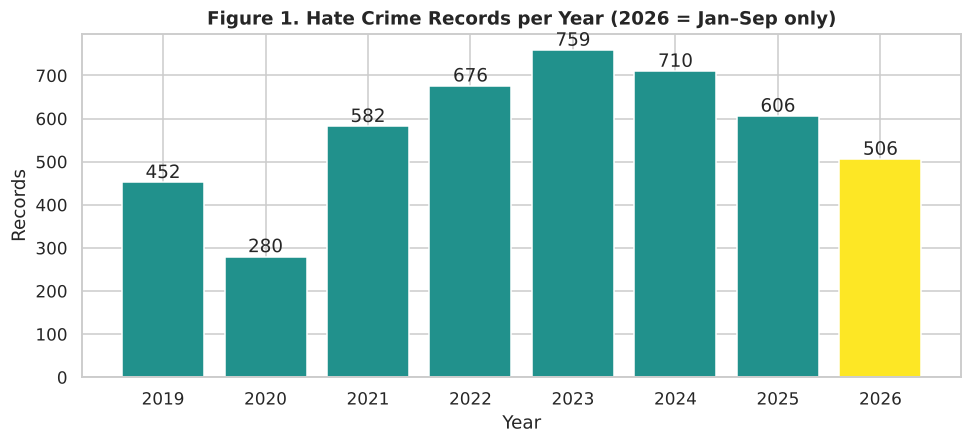

In [5]:
y = d[d.year.between(2019,2026)].groupby('year').size()
fig,ax = plt.subplots(figsize=(9,4.2))
bars = ax.bar(y.index.astype(str), y.values, color=['#21918c']*7+['#fde725'])
ax.bar_label(bars)
ax.set(title='Figure 1. Hate Crime Records per Year (2026 = Jan–Sep only)', xlabel='Year', ylabel='Records')
plt.tight_layout(); plt.show()

Records peaked in 2023 (759) and have fallen since (710 in 2024, 606 in 2025). 2026 has 506 records through September, which is on pace to exceed 2025. 2020 (280) is the low point.

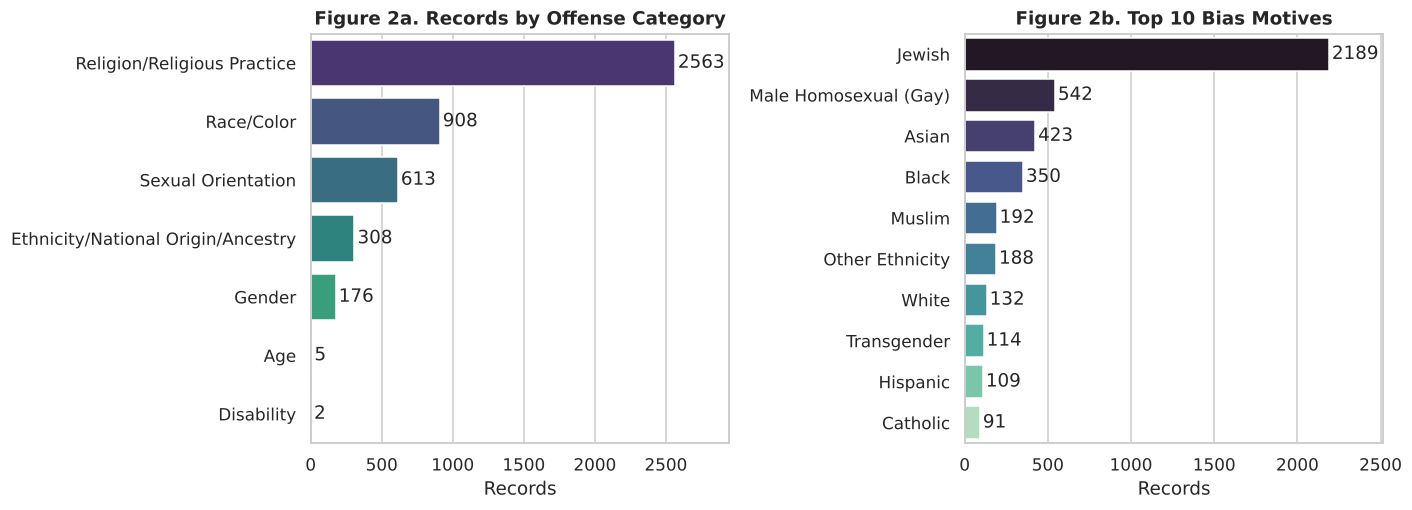

In [6]:
fig,axs = plt.subplots(1,2,figsize=(13,4.8))
c = d.category.value_counts(); sns.barplot(x=c.values,y=c.index,ax=axs[0],palette='viridis'); [axs[0].bar_label(k,padding=2) for k in axs[0].containers]
axs[0].set(title='Figure 2a. Records by Offense Category',xlabel='Records',ylabel=''); axs[0].set_xlim(0,c.max()*1.15)
b = d.bias.value_counts().head(10); sns.barplot(x=b.values,y=b.index,ax=axs[1],palette='mako'); [axs[1].bar_label(k,padding=2) for k in axs[1].containers]
axs[1].set(title='Figure 2b. Top 10 Bias Motives',xlabel='Records',ylabel=''); axs[1].set_xlim(0,b.max()*1.15)
plt.tight_layout(); plt.show()

Religion-based crimes are 56% of records (2,563), and anti-Jewish incidents alone are 2,189 (48%). Race/Color (908) and Sexual Orientation (613) follow. Age and Disability have only 7 records combined, so they are too sparse for later modeling without grouping.

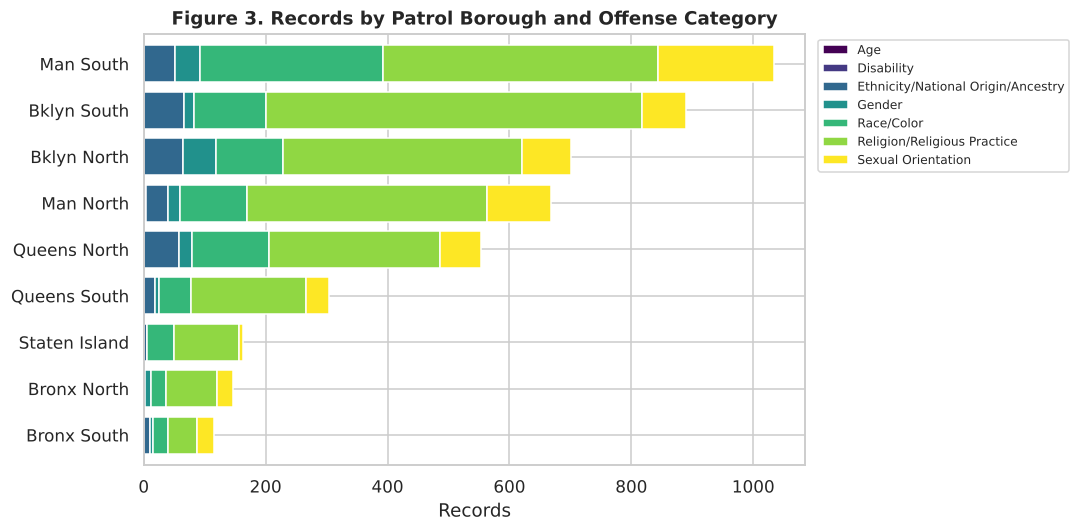

In [7]:
ct = pd.crosstab(d.borough, d.category); ct = ct.loc[ct.sum(1).sort_values().index]
ct.plot(kind='barh', stacked=True, figsize=(10,5), colormap='viridis', width=.8)
plt.title('Figure 3. Records by Patrol Borough and Offense Category'); plt.xlabel('Records'); plt.ylabel('')
plt.legend(bbox_to_anchor=(1.01,1), loc='upper left', fontsize=8); plt.tight_layout(); plt.show()

Manhattan South (1,034) and Brooklyn South (890) have the most records, while the Bronx boroughs have the fewest. Brooklyn and Manhattan together account for most religion-based incidents.

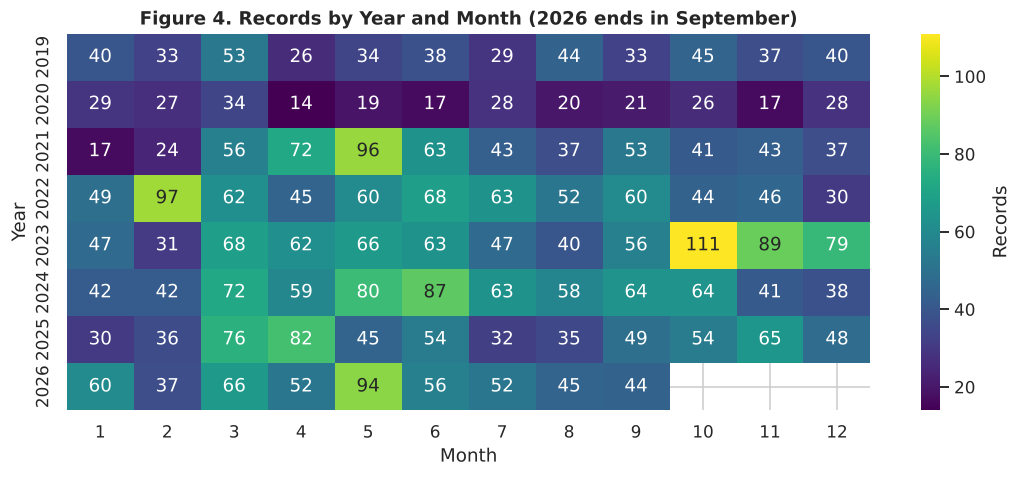

In [8]:
p = d[d.year.between(2019,2026)].pivot_table(index='year', columns='month', values='complaint_id', aggfunc='size')
fig,ax = plt.subplots(figsize=(10,4.5))
sns.heatmap(p, annot=True, fmt='.0f', cmap='viridis', cbar_kws={'label':'Records'}, ax=ax)
ax.set(title='Figure 4. Records by Year and Month (2026 ends in September)', xlabel='Month', ylabel='Year')
plt.tight_layout(); plt.show()

Counts are usually highest in spring and early summer (March to June) and lowest in winter. Several single months stand out, such as May 2021 (96) and October 2023 (111), suggesting event-driven spikes.

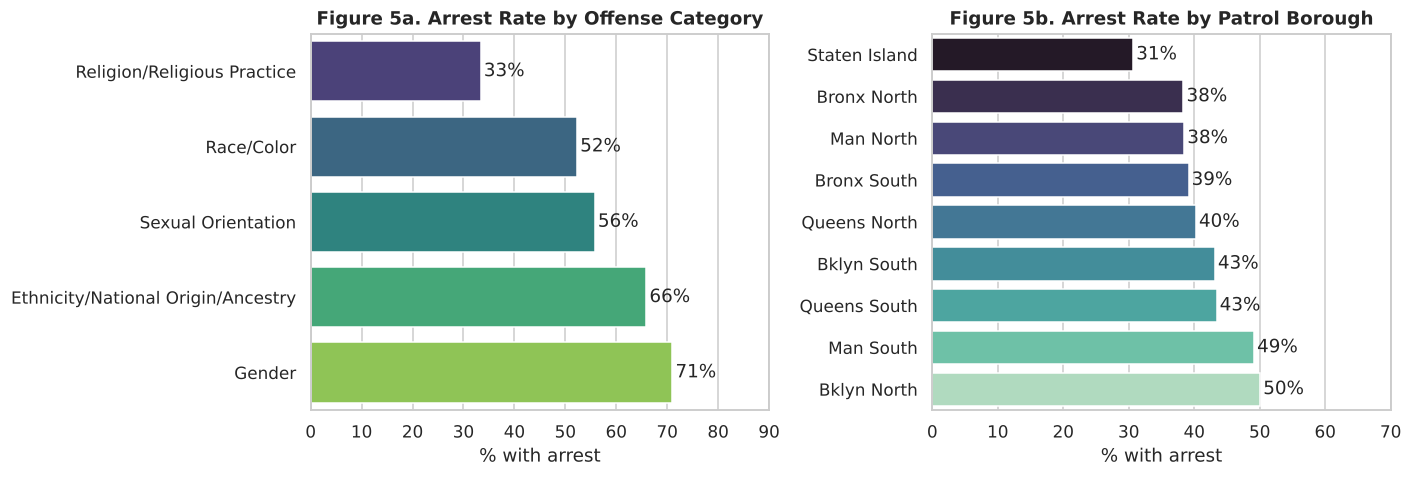

In [9]:
fig,axs = plt.subplots(1,2,figsize=(13,4.5))
a = d.groupby('category').arrested.agg(['mean','size']).query('size>=100')['mean'].mul(100).sort_values()
sns.barplot(x=a.values,y=a.index,ax=axs[0],palette='viridis'); [axs[0].bar_label(k,fmt='%.0f%%',padding=2) for k in axs[0].containers]
axs[0].set(title='Figure 5a. Arrest Rate by Offense Category',xlabel='% with arrest',ylabel='',xlim=(0,90))
a2 = d.groupby('borough').arrested.mean().mul(100).sort_values()
sns.barplot(x=a2.values,y=a2.index,ax=axs[1],palette='mako'); [axs[1].bar_label(k,fmt='%.0f%%',padding=2) for k in axs[1].containers]
axs[1].set(title='Figure 5b. Arrest Rate by Patrol Borough',xlabel='% with arrest',ylabel='',xlim=(0,70))
plt.tight_layout(); plt.show()

The overall arrest rate is 44%. It is lowest for religion-based crimes (33%) and highest for gender (71%) and ethnicity/national origin (66%) crimes. Brooklyn North (50%) and Manhattan South (49%) have the highest borough rates, and Staten Island (31%) the lowest.

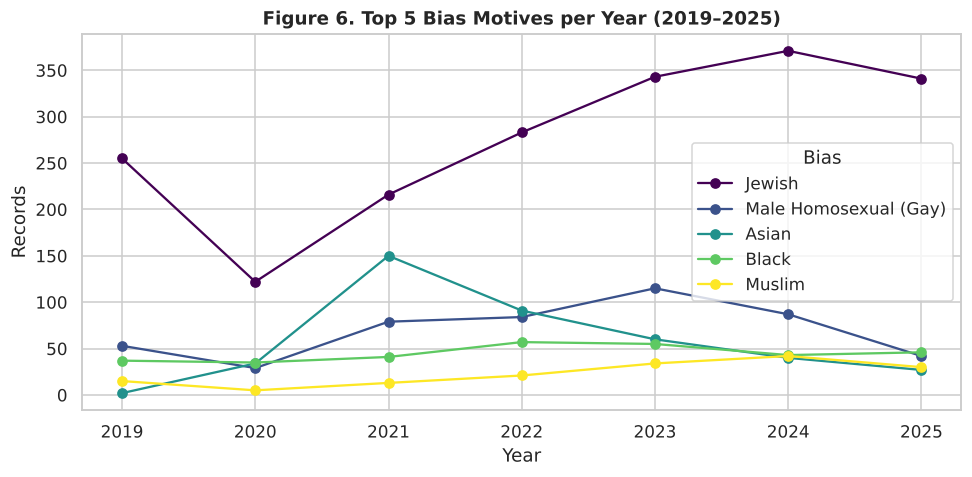

In [10]:
top = d.bias.value_counts().head(5).index
t = d[d.bias.isin(top)&d.year.between(2019,2025)].pivot_table(index='year',columns='bias',values='complaint_id',aggfunc='size')[top]
t.plot(marker='o', figsize=(9,4.5), colormap='viridis')
plt.title('Figure 6. Top 5 Bias Motives per Year (2019–2025)'); plt.ylabel('Records'); plt.xlabel('Year'); plt.legend(title='Bias')
plt.tight_layout(); plt.show()

Anti-Jewish incidents dominate every year and drive the overall trend, including the 2021 to 2023 rise. Anti-Asian incidents rose from 2020 to 2021 and have declined since. Other motives are comparatively stable.

## 5. Key Findings
- 4,575 offense records (4,217 unique complaints), 14 columns, with missing values only in the arrest fields.
- Records peaked in 2023 and have declined since; 2026 is partial.
- Religion-based crimes, mainly anti-Jewish, are over half of all records.
- Manhattan South and Brooklyn South have the most records; Brooklyn North and Manhattan South have the highest arrest rates.
- Arrest rates differ by offense type, with religion-based crimes the lowest at 33%.
- **For later modeling:** `arrested` is a natural target; class imbalance in `category` (Age, Disability) and the repeated complaint IDs need attention.

## 6. Limitations
The data covers confirmed incidents only, 2026 is incomplete, and arrest dates may not belong to the same incident as the report date.

## References
NYC Open Data. (2026). *NYPD hate crimes* [Data set]. New York City Police Department. https://data.cityofnewyork.us/Public-Safety/NYPD-Hate-Crimes/bqiq-cu78